Data Preprocessing

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Load the original dataset
df = pd.read_csv('Global.csv')

# Encode Categorical Columns (Convert non-numeric values)
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()  # Find all object columns

label_encoders = {}
for col in categorical_columns:
    label_encoders[col] = LabelEncoder()
    df[col] = label_encoders[col].fit_transform(df[col].astype(str))  # Convert to string before encoding

# Handle Missing Values
df.fillna(df.mean(), inplace=True)

# Normalize Numerical Features using Min-Max scaling to bring values in the range [0, 1]
scaler = MinMaxScaler()
numerical_columns = df.select_dtypes(include=['number']).columns
df[numerical_columns] = scaler.fit_transform(df[numerical_columns])

Save the processed dataset
df.to_csv('Rerun_preprocess/processed_dataset.csv', index=False)

print("Preprocessing complete. Processed dataset saved as 'processed_dataset.csv'.")


Preprocessing complete. Processed dataset saved as 'processed_dataset.csv'.


Feature Selection based on correlation threshold (0.1)

In [ ]:
# Load the preprocessed dataset
df = pd.read_csv('Rerun_preprocess/processed_dataset.csv')

# Define the target variable (class label)
target_column = 'Label'

# Calculate correlation matrix for all features
correlations = df.corr()

target_correlations = correlations[target_column]

threshold = 0.1

# Select features with correlation above the threshold (excluding the target column)
selected_features = target_correlations[abs(target_correlations) > threshold].index
selected_features = selected_features[selected_features != target_column]

df_filtered = df[selected_features].copy()
df_filtered.loc[:, target_column] = df[target_column] 

# Save the filtered dataset
df_filtered.to_csv('Rerun_preprocess/filtered_dataset.csv', index=False)

print(f"Selected features based on correlation threshold ({threshold}):")
print(selected_features)
print(f"Filtered dataset saved as 'filtered_dataset.csv'.")


Selected features based on correlation threshold (0.1):
Index(['X', 'Dur', 'RunTime', 'Mean', 'Sum', 'Min', 'Max', 'sTtl', 'dTtl',
       'dHops', 'TotPkts', 'SrcPkts', 'DstPkts', 'TotBytes', 'SrcBytes',
       'DstBytes', 'sMeanPktSz', 'Loss', 'SrcLoss', 'DstLoss', 'pLoss',
       'State', 'SrcWin', 'SrcTCPBase', 'TcpRtt', 'SynAck'],
      dtype='object')
Filtered dataset saved as 'filtered_dataset.csv'.


Feature Correlation Heatmap

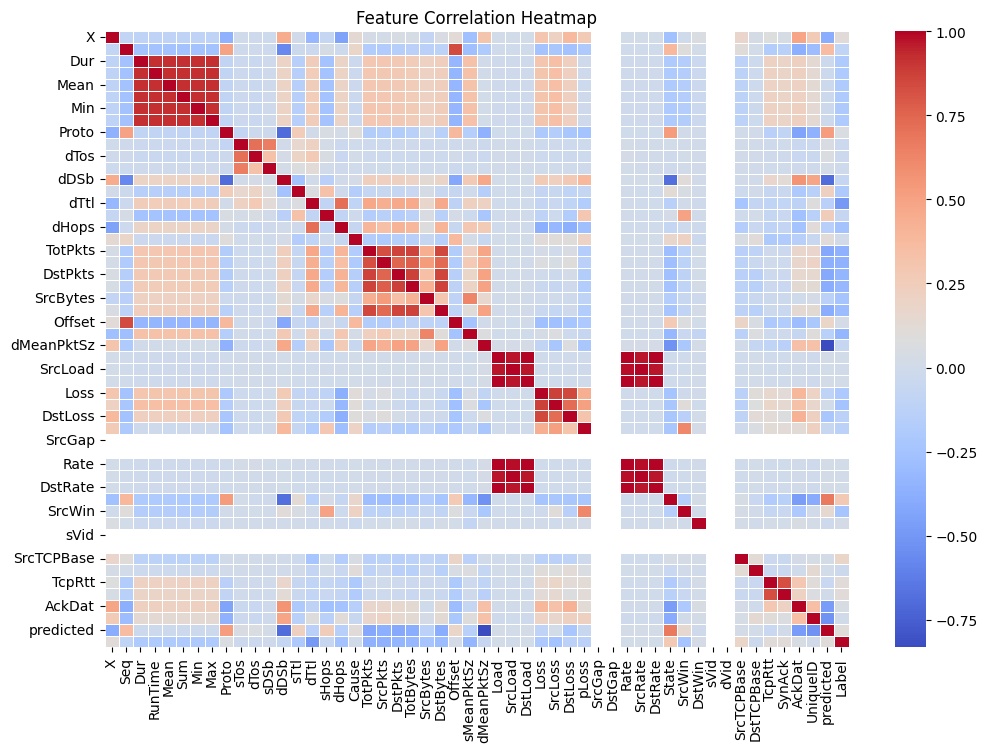

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('Rerun_preprocess/processed_dataset.csv')

# Compute correlation matrix
correlation_matrix = df.corr()

# Set figure size
plt.figure(figsize=(12, 8))

# Create heatmap
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, linewidths=0.5)

# Title
plt.title("Feature Correlation Heatmap")

# Show plot
plt.show()


Feature Selection based on BPSO

In [ ]:
from pyswarm import pso
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import pandas as pd 
import numpy as np

# Load Filtered Dataset
df = pd.read_csv('Rerun_preprocess/filtered_dataset.csv')

# Separate features (X) from target label (y)
X = df.drop(columns=['Label'])
y = df['Label']

# Define the fitness function for BPSO
def fitness_function(selected_features):
    # Convert binary particle positions to boolean mask
    mask = selected_features > 0.5
    
    # If no features are selected, return a low fitness score
    if mask.sum() == 0:
        return 1.0

    # Use only the selected features
    X_selected = X.iloc[:, mask]
    
    # Evaluate accuracy using cross-validation
    model = DecisionTreeClassifier(random_state=42)
    score = cross_val_score(model, X_selected, y, cv=5, scoring='accuracy').mean()
    
    return 1 - score

# Run BPSO Optimization
n_features = X.shape[1]
lb = [0] * n_features 
ub = [1] * n_features
best_features, _ = pso(fitness_function, lb, ub, swarmsize=20, maxiter=50)

# Apply Best Feature Mask
selected_mask = best_features > 0.5
selected_features = X.columns[selected_mask]

df_bpso_filtered = df[selected_features]
df_bpso_filtered['Label'] = y

# Save the new dataset
df_bpso_filtered.to_csv('Rerun_preprocess/bpso_filtered_dataset.csv', index=False)

# Print results
print(f"Selected features after BPSO: {list(selected_features)}")
print("BPSO filtered dataset saved as 'bpso_filtered_dataset.csv'.")


Stopping search: maximum iterations reached --> 50


C:\Users\KYRIACOS PLYSIS\AppData\Local\Temp\ipykernel_71980\1467064511.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bpso_filtered['Label'] = y


Selected features after BPSO: ['X', 'Mean', 'Min', 'Max', 'dHops', 'DstPkts', 'TotBytes', 'sMeanPktSz', 'SrcWin', 'TcpRtt']
BPSO filtered dataset saved as 'bpso_filtered_dataset.csv'.


Καθώς ο αλγόριθμος Binary Particle Swarm Optimization (BPSO) είναι στοχαστικός, η εκτέλεσή του μπορεί να οδηγήσει σε διαφορετικά σύνολα χαρακτηριστικών κάθε φορά. Για να αντιμετωπιστεί αυτή η μεταβλητότητα, εκτελέσαμε τον αλγόριθμο πολλαπλές φορές και παρατηρήσαμε τα χαρακτηριστικά που εμφανίζονταν συχνότερα μεταξύ των αποτελεσμάτων.

Επομένως, επιλέχθηκε το σύνολο χαρακτηριστικών που περιλάμβανε τα περισσότερα κοινά στοιχεία από όλες τις εκτελέσεις. Με αυτόν τον τρόπο, διασφαλίστηκε ότι το τελικό υποσύνολο είναι πιο αντιπροσωπευτικό και λιγότερο ευαίσθητο στη τυχαιότητα του αλγορίθμου.

Correlation Matrix of BPSO-Selected Features

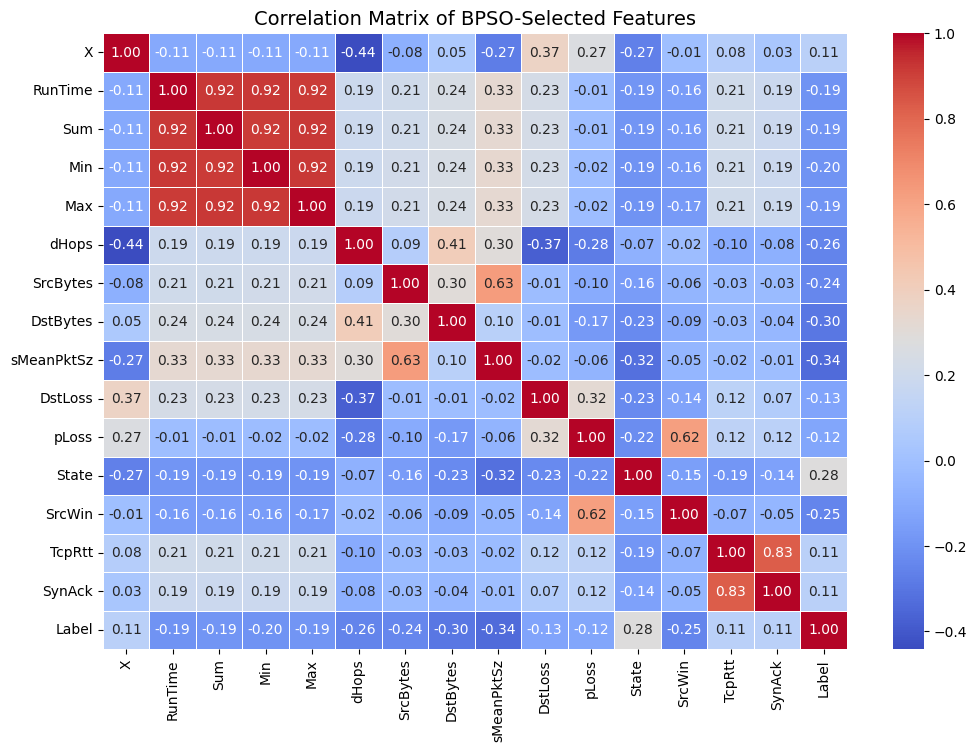

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the BPSO-filtered dataset
file_path = 'FL_datasets/bpso_filtered_dataset.csv' 
df_bpso = pd.read_csv(file_path)

# Compute the correlation matrix
correlation_matrix = df_bpso.corr()

# Set up the figure
plt.figure(figsize=(12, 8))

# Create a heatmap
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

# Set title
plt.title("Correlation Matrix of BPSO-Selected Features", fontsize=14)

# Show the plot
plt.show()



Test the subsets 

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load datasets
df_processed = pd.read_csv("FL_datasets/processed_dataset.csv")            # has 'predicted'
df_bpso = pd.read_csv("FL_datasets/bpso_filtered_dataset.csv")             # filtered version

# Add the 'predicted' column for stratification
df_bpso_with_pred = df_bpso.copy()
df_bpso_with_pred["predicted"] = df_processed.loc[df_bpso.index, "predicted"]

# Show class distribution BEFORE split
print("Class distribution BEFORE split:")
print(df_bpso_with_pred["predicted"].value_counts().sort_index())
print()

# Stratified train/test split
df_train, df_test = train_test_split(
    df_bpso_with_pred,
    test_size=0.2,
    stratify=df_bpso_with_pred["predicted"],
    random_state=42
)

# Show class distributions AFTER split
print("Class distribution in TRAIN set:")
print(df_train["predicted"].value_counts().sort_index())
print()

print("Class distribution in TEST set:")
print(df_test["predicted"].value_counts().sort_index())
print()

# Save full train/test datasets (without 'predicted')
df_train.drop(columns=["predicted"]).to_csv("FL_datasets/bpso_train_dataset.csv", index=False)
df_test.drop(columns=["predicted"]).to_csv("FL_5GSlices_subsets/global_test_set.csv", index=False)

print(f"✅ Saved training set: {len(df_train)} samples")
print(f"✅ Saved test set: {len(df_test)} samples\n")


# Create 3 FL subsets based on network slice

df_embb  = df_train[df_train["predicted"] == 0.0].drop(columns=["predicted"])
df_mmtc  = df_train[df_train["predicted"] == 0.5].drop(columns=["predicted"])
df_urllc = df_train[df_train["predicted"] == 1.0].drop(columns=["predicted"])

df_embb.to_csv("FL_5GSlices_subsets/eMBB_bpso_global.csv", index=False)
df_mmtc.to_csv("FL_5GSlices_subsets/mMTC_bpso_global.csv", index=False)
df_urllc.to_csv("FL_5GSlices_subsets/URLLC_bpso_global.csv", index=False)

print("✅ Created slice-based FL training subsets:")
print(f"  eMBB:  {len(df_embb)} samples")
print(f"  mMTC:  {len(df_mmtc)} samples")
print(f"  URLLC: {len(df_urllc)} samples\n")

# Create 3 slice-based test sets

test_embb  = df_test[df_test["predicted"] == 0.0].drop(columns=["predicted"])
test_mmtc  = df_test[df_test["predicted"] == 0.5].drop(columns=["predicted"])
test_urllc = df_test[df_test["predicted"] == 1.0].drop(columns=["predicted"])

test_embb.to_csv("FL_5GSlices_subsets/eMBB_test_set.csv", index=False)
test_mmtc.to_csv("FL_5GSlices_subsets/mMTC_test_set.csv", index=False)
test_urllc.to_csv("FL_5GSlices_subsets/URLLC_test_set.csv", index=False)

print("✅ Created slice-based test subsets:")
print(f"  eMBB Test:  {len(test_embb)} samples")
print(f"  mMTC Test:  {len(test_mmtc)} samples")
print(f"  URLLC Test: {len(test_urllc)} samples")


📊 Class distribution BEFORE split:
predicted
0.0    5808
0.5    4615
1.0    4033
Name: count, dtype: int64

📊 Class distribution in TRAIN set:
predicted
0.0    4646
0.5    3692
1.0    3226
Name: count, dtype: int64

📊 Class distribution in TEST set:
predicted
0.0    1162
0.5     923
1.0     807
Name: count, dtype: int64

✅ Saved training set: 11564 samples
✅ Saved test set: 2892 samples

✅ Created slice-based FL training subsets:
  eMBB:  4646 samples
  mMTC:  3692 samples
  URLLC: 3226 samples

✅ Created slice-based test subsets:
  eMBB Test:  1162 samples
  mMTC Test:  923 samples
  URLLC Test: 807 samples


Create 3 equal in samples subsets for the second federated learning model (randomly sampled (no ordering bias)

In [12]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split

# Load the BPSO-filtered training dataset
df = pd.read_csv("FL_datasets/bpso_train_dataset.csv")

# Shuffle the dataset to ensure randomness
df_shuffled = df.sample(frac=1.0, random_state=42).reset_index(drop=True)

# Compute split sizes
n = len(df_shuffled)
split_size = n // 3

# Split into 3 equal parts
subset1 = df_shuffled.iloc[:split_size]
subset2 = df_shuffled.iloc[split_size:2*split_size]
subset3 = df_shuffled.iloc[2*split_size:]

# Create output folder
os.makedirs("FL_EqSplit_subsets", exist_ok=True)

# Save each subset
subset1.to_csv("FL_EqSplit_subsets/split1.csv", index=False)
subset2.to_csv("FL_EqSplit_subsets/split2.csv", index=False)
subset3.to_csv("FL_EqSplit_subsets/split3.csv", index=False)

print("✅ Created 3 equal random subsets:")
print(f"  Subset 1: {len(subset1)} samples")
print(f"  Subset 2: {len(subset2)} samples")
print(f"  Subset 3: {len(subset3)} samples")



✅ Created 3 equal random subsets:
  Subset 1: 3854 samples
  Subset 2: 3854 samples
  Subset 3: 3856 samples


Create Validation and Test dataset for federated learning

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load your global test set
df = pd.read_csv("FL_5GSlices_subsets/global_test_set.csv")

# Split into 50% validation and 50% true test set
val_df, test_df = train_test_split(df, test_size=0.5, random_state=42, shuffle=True)

# Save the resulting splits
val_df.to_csv("FL_5GSlices_subsets/global_val_set.csv", index=False)
test_df.to_csv("FL_5GSlices_subsets/global_true_test_set.csv", index=False)

print("✅ Split complete! Saved:")
print("- global_val_set.csv (for validation during FL)")
print("- global_true_test_set.csv (for final testing after training)")


✅ Split complete! Saved:
- global_val_set.csv (for validation during FL)
- global_true_test_set.csv (for final testing after training)


FEDERATED LEARNING 5G SLICES FEDAVGM/FEDADAM

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, fbeta_score
from utils import build_model, load_data

# Load the test set
_, X_test, _, y_test, _ = load_data("FL_5GSlices_subsets/global_true_test_set.csv")

# Build model
model = build_model(input_dim=X_test.shape[1])

# # Load saved weights from FedAvg training
# model.load_weights("saved_models/fedavg_models/Slices/round_9_acc_89.31.weights.h5")

# # Load saved weights from FedAvgM training
# model.load_weights("saved_models/fedavgm_models/Splits/round_22_acc_96.55.weights.h5") 

# Load saved weights from FedAdam training
model.load_weights("saved_models/fedadam_models/Slices/round_5_acc_93.96.weights.h5")

# Predicts
y_pred_probs = model.predict(X_test)

# Handle label format correctly
if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = y_test.astype(int)

y_pred = np.argmax(y_pred_probs, axis=1)

# Evaluate
loss, accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"\n🎯 Final Test Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, digits=4))

# F2 Score
f2 = fbeta_score(y_true, y_pred, beta=2, average="weighted")
print(f"\n🔍 Weighted F2 Score: {f2:.4f}")



c:\Users\KYRIACOS PLYSIS\Desktop\Thesis\MyProject3\venv\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step  
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9253 - loss: 0.2079  

🎯 Final Test Accuracy: 92.76%

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.4793    1.0000    0.6480       139
           1     0.0000    0.0000    0.0000       151

    accuracy                         0.4793       290
   macro avg     0.2397    0.5000    0.3240       290
weighted avg     0.2297    0.4793    0.3106       290


🔍 Weighted F2 Score: 0.3938


c:\Users\KYRIACOS PLYSIS\Desktop\Thesis\MyProject3\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\KYRIACOS PLYSIS\Desktop\Thesis\MyProject3\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\KYRIACOS PLYSIS\Desktop\Thesis\MyProject3\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average,